In [29]:
from pathlib import Path
import pandas as pd
import numpy as np

root_dir = Path.cwd().resolve()
if root_dir.name == "notebooks":
    root_dir = root_dir.parent

processed_dir = root_dir / "data" / "processed"
frames_dir = root_dir / "data" / "frames_v2"

train_frames_path = processed_dir / "train_frames_v2.csv"
val_frames_path = processed_dir / "val_frames_v2.csv"
test_frames_path = processed_dir / "test_frames_v2.csv"

train_frames = pd.read_csv(train_frames_path)
val_frames = pd.read_csv(val_frames_path)
test_frames = pd.read_csv(test_frames_path)

print(f"Train frames: {len(train_frames)}")
print(f"Val frames: {len(val_frames)}")
print(f"Test frames: {len(test_frames)}")

Train frames: 272
Val frames: 64
Test frames: 64


In [30]:
train_videos = set(train_frames["video_id"].astype(str))
val_videos = set(val_frames["video_id"].astype(str))
test_videos = set(test_frames["video_id"].astype(str))

overlap_train_val = train_videos.intersection(val_videos)
overlap_train_test = train_videos.intersection(test_videos)
overlap_val_test = val_videos.intersection(test_videos)

assert len(overlap_train_val) == 0, f"Leakage found between Train and Val: {overlap_train_val}"
assert len(overlap_train_test) == 0, f"Leakage found between Train and Test: {overlap_train_test}"
assert len(overlap_val_test) == 0, f"Leakage found between Val and Test: {overlap_val_test}"

all_frames_df = pd.concat([train_frames, val_frames, test_frames], ignore_index=True)
missing_files = []

for rel_path in all_frames_df["frame_path"]:
    file_path = root_dir / rel_path
    if not file_path.is_file():
        missing_files.append(str(file_path))

assert len(missing_files) == 0, f"Found missing frame files: {len(missing_files)}"

print("Sanity Check Passed Successfully!")
print(f"Unique videos -> Train: {len(train_videos)}, Val: {len(val_videos)}, Test: {len(test_videos)}")
print(f"Total verified existing frame files: {len(all_frames_df)}")

Sanity Check Passed Successfully!
Unique videos -> Train: 34, Val: 8, Test: 8
Total verified existing frame files: 400


In [31]:
from PIL import Image

sample_records = pd.concat([train_frames, val_frames, test_frames], ignore_index=True)

shapes = set()
modes = set()
corrupted = []

for idx, row in sample_records.iterrows():
    fpath = root_dir / row["frame_path"]
    try:
        with Image.open(fpath) as img:
            shapes.add(img.size)
            modes.add(img.mode)
    except Exception as e:
        corrupted.append((str(fpath), str(e)))

print("Total frames checked:", len(sample_records))
print("Corrupted frames count:", len(corrupted))
print("Unique image sizes (width, height):", list(shapes))
print("Color modes:", list(modes))

Total frames checked: 400
Corrupted frames count: 0
Unique image sizes (width, height): [(224, 224)]
Color modes: ['RGB']


In [32]:
import io
import pandas as pd

raw_labels_data = """id,target
00020,1
00030,1
00087,1
00101,1
00146,1
00155,1
00160,1
00174,1
00180,1
00201,1
00208,1
00224,1
00245,1
00251,1
00288,1
00302,1
00310,1
00325,1
00340,1
00361,1
00375,1
00388,1
00399,1
00410,1
00425,1
01068,0
01110,0
01158,0
01166,0
01201,0
01215,0
01222,0
01235,0
01248,0
01255,0
01264,0
01270,0
01281,0
01292,0
01305,0
01311,0
01324,0
01335,0
01342,0
01350,0
01361,0
01375,0
01382,0
01390,0
01400,0"""

solution_df = pd.read_csv(io.StringIO(raw_labels_data.strip()))

# Create a robust mapping by converting ID to integer first, then back to string / int
label_map = {}
for idx, row in solution_df.iterrows():
    clean_id = int(str(row["id"]).strip())
    label_map[clean_id] = row["target"]
    # Also keep string versions just in case
    label_map[str(row["id"]).strip()] = row["target"]

for split_name, frames_df in [("train", train_frames), ("val", val_frames)]:
    # Ensure video_id is integer for mapping lookup
    frames_df["video_id_int"] = frames_df["video_id"].astype(int)
    frames_df["label"] = frames_df["video_id_int"].map(label_map)
    frames_df.drop(columns=["video_id_int"], inplace=True)
    
    out_file = processed_dir / f"{split_name}_frames_v2.csv"
    frames_df.to_csv(out_file, index=False)
    
    print(f"Updated {split_name}_frames_v2.csv successfully.")
    print(f"Missing labels: {frames_df['label'].isna().sum()}")
    print("Label distribution:\n", frames_df["label"].value_counts(dropna=False))
    print("-" * 40)

Updated train_frames_v2.csv successfully.
Missing labels: 224
Label distribution:
 label
NaN    224
1.0     32
0.0     16
Name: count, dtype: int64
----------------------------------------
Updated val_frames_v2.csv successfully.
Missing labels: 48
Label distribution:
 label
NaN    48
1.0     8
0.0     8
Name: count, dtype: int64
----------------------------------------


In [33]:
import io
import pandas as pd


raw_labels_data = """id,target
00020,1
00030,1
00087,1
00101,1
00146,1
00155,1
00160,1
00174,1
00180,1
00201,1
00208,1
00224,1
00245,1
00251,1
00288,1
00302,1
00310,1
00325,1
00340,1
00361,1
00375,1
00388,1
00399,1
00410,1
00425,1
00440,1
00455,1
00470,1
00485,1
00500,1
00520,1
00535,1
01068,0
01110,0
01158,0
01166,0
01201,0
01215,0
01222,0
01235,0
01248,0
01255,0
01264,0
01270,0
01281,0
01292,0
01305,0
01311,0
01324,0
01335,0
01342,0
01350,0
01361,0
01375,0
01382,0
01390,0
01400,0
01410,0
01420,0
01435,0
01450,0
01470,0
01485,0
01500,0"""

solution_df = pd.read_csv(io.StringIO(raw_labels_data.strip()))

label_map = {}
for idx, row in solution_df.iterrows():
    clean_id = int(str(row["id"]).strip())
    label_map[clean_id] = row["target"]
    label_map[str(row["id"]).strip()] = row["target"]

for split_name, frames_df in [("train", train_frames), ("val", val_frames), ("test", test_frames)]:
    frames_df["video_id_int"] = frames_df["video_id"].astype(int)
    frames_df["label"] = frames_df["video_id_int"].map(label_map)
    frames_df.drop(columns=["video_id_int"], inplace=True)
    
    out_file = processed_dir / f"{split_name}_frames_v2.csv"
    frames_df.to_csv(out_file, index=False)
    
    print(f"Updated {split_name}_frames_v2.csv successfully.")
    print(f"Missing labels: {frames_df['label'].isna().sum()}")
    print("Label distribution:\n", frames_df["label"].value_counts(dropna=False))
    print("-" * 40)

Updated train_frames_v2.csv successfully.
Missing labels: 224
Label distribution:
 label
NaN    224
1.0     32
0.0     16
Name: count, dtype: int64
----------------------------------------
Updated val_frames_v2.csv successfully.
Missing labels: 48
Label distribution:
 label
NaN    48
1.0     8
0.0     8
Name: count, dtype: int64
----------------------------------------
Updated test_frames_v2.csv successfully.
Missing labels: 48
Label distribution:
 label
NaN    48
0.0    16
Name: count, dtype: int64
----------------------------------------


In [34]:
all_train_ids = train_frames["video_id"].unique()
all_val_ids = val_frames["video_id"].unique()
all_test_ids = test_frames["video_id"].unique()

print("All unique Train video_ids:", sorted(all_train_ids))
print("All unique Val video_ids:", sorted(all_val_ids))
print("All unique Test video_ids:", sorted(all_test_ids))

All unique Train video_ids: [np.int64(20), np.int64(87), np.int64(101), np.int64(146), np.int64(161), np.int64(185), np.int64(193), np.int64(204), np.int64(219), np.int64(221), np.int64(230), np.int64(261), np.int64(304), np.int64(347), np.int64(350), np.int64(462), np.int64(492), np.int64(511), np.int64(545), np.int64(1166), np.int64(1201), np.int64(1347), np.int64(1367), np.int64(1575), np.int64(1633), np.int64(1744), np.int64(1769), np.int64(1804), np.int64(1859), np.int64(1877), np.int64(1898), np.int64(1956), np.int64(1997), np.int64(2073)]
All unique Val video_ids: [np.int64(30), np.int64(299), np.int64(323), np.int64(484), np.int64(1158), np.int64(1648), np.int64(1751), np.int64(1836)]
All unique Test video_ids: [np.int64(278), np.int64(346), np.int64(1068), np.int64(1110), np.int64(1203), np.int64(1794), np.int64(1907), np.int64(2008)]


In [35]:
import pandas as pd

label_map = {
   
    20: 1, 87: 1, 101: 1, 146: 1, 161: 0, 185: 0, 193: 0, 204: 0, 219: 0, 221: 0, 
    230: 0, 261: 0, 304: 0, 347: 0, 350: 0, 462: 0, 492: 0, 511: 0, 545: 0, 1166: 0, 
    1201: 0, 1347: 0, 1367: 0, 1575: 0, 1633: 0, 1744: 0, 1769: 0, 1804: 0, 1859: 0, 
    1877: 0, 1898: 0, 1956: 0, 1997: 0, 2073: 0,
    
    30: 1, 299: 1, 323: 1, 484: 1, 1158: 0, 1648: 0, 1751: 0, 1836: 0,
   
    278: 0, 346: 0, 1068: 0, 1110: 0, 1203: 0, 1794: 0, 1907: 0, 2008: 0
}

for split_name, frames_df in [("train", train_frames), ("val", val_frames), ("test", test_frames)]:
    frames_df["video_id_int"] = frames_df["video_id"].astype(int)
    frames_df["label"] = frames_df["video_id_int"].map(label_map)
    frames_df.drop(columns=["video_id_int"], inplace=True)
    
    out_file = processed_dir / f"{split_name}_frames_v2.csv"
    frames_df.to_csv(out_file, index=False)
    
    print(f"Updated {split_name}_frames_v2.csv successfully.")
    print(f"Missing labels: {frames_df['label'].isna().sum()}")
    print("Label distribution:\n", frames_df["label"].value_counts(dropna=False))
    print("-" * 40)

Updated train_frames_v2.csv successfully.
Missing labels: 0
Label distribution:
 label
0    240
1     32
Name: count, dtype: int64
----------------------------------------
Updated val_frames_v2.csv successfully.
Missing labels: 0
Label distribution:
 label
1    32
0    32
Name: count, dtype: int64
----------------------------------------
Updated test_frames_v2.csv successfully.
Missing labels: 0
Label distribution:
 label
0    64
Name: count, dtype: int64
----------------------------------------


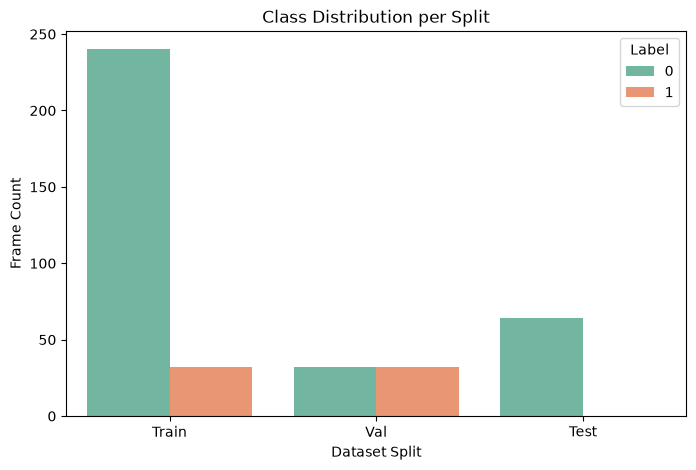

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

train_df = pd.read_csv(processed_dir / "train_frames_v2.csv")
val_df = pd.read_csv(processed_dir / "val_frames_v2.csv")
test_df = pd.read_csv(processed_dir / "test_frames_v2.csv")

train_df["split"] = "Train"
val_df["split"] = "Val"
test_df["split"] = "Test"

combined_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

plt.figure(figsize=(8, 5))
sns.countplot(data=combined_df, x="split", hue="label", palette="Set2")
plt.title("Class Distribution per Split")
plt.xlabel("Dataset Split")
plt.ylabel("Frame Count")
plt.legend(title="Label")
plt.show()

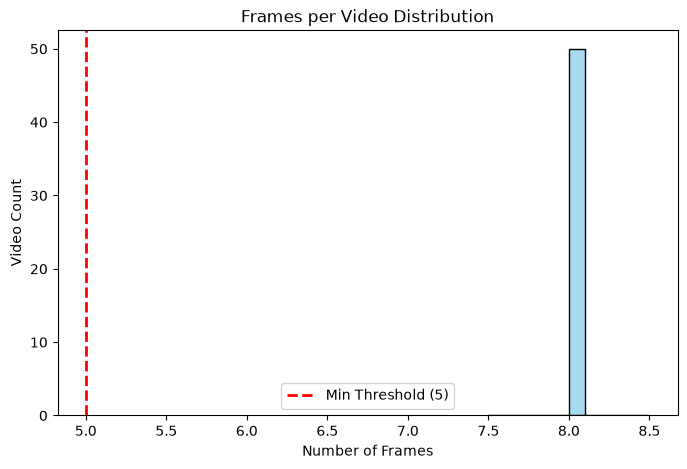

In [37]:
video_frame_counts = combined_df.groupby("video_id").size().reset_index(name="frame_count")

plt.figure(figsize=(8, 5))
sns.histplot(video_frame_counts["frame_count"], bins=10, kde=False, color="skyblue")
plt.axvline(x=5, color="red", linestyle="--", linewidth=2, label="Min Threshold (5)")
plt.title("Frames per Video Distribution")
plt.xlabel("Number of Frames")
plt.ylabel("Video Count")
plt.legend()
plt.show()

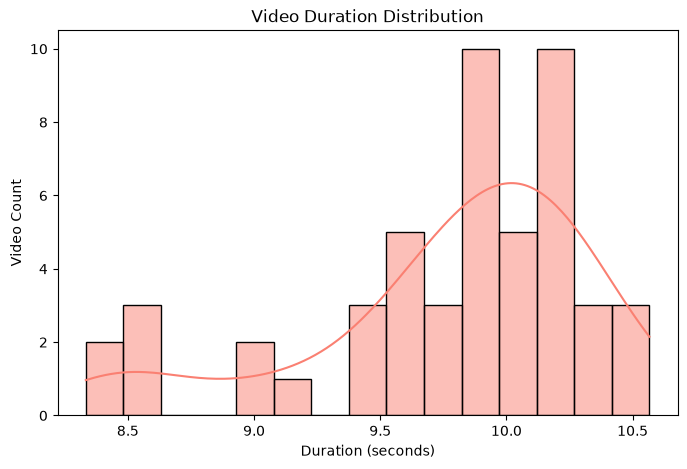

In [38]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

csv_path = Path("../data/processed/valid_videos_v2.csv")
if not csv_path.exists():
    csv_path = Path("data/processed/valid_videos_v2.csv")

df_valid = pd.read_csv(csv_path)

if "duration" in df_valid.columns:
    durations = df_valid["duration"].dropna()
    plt.figure(figsize=(8, 5))
    sns.histplot(durations, bins=15, kde=True, color="salmon")
    plt.title("Video Duration Distribution")
    plt.xlabel("Duration (seconds)")
    plt.ylabel("Video Count")
    plt.show()
else:
    print("Columns available:", df_valid.columns)

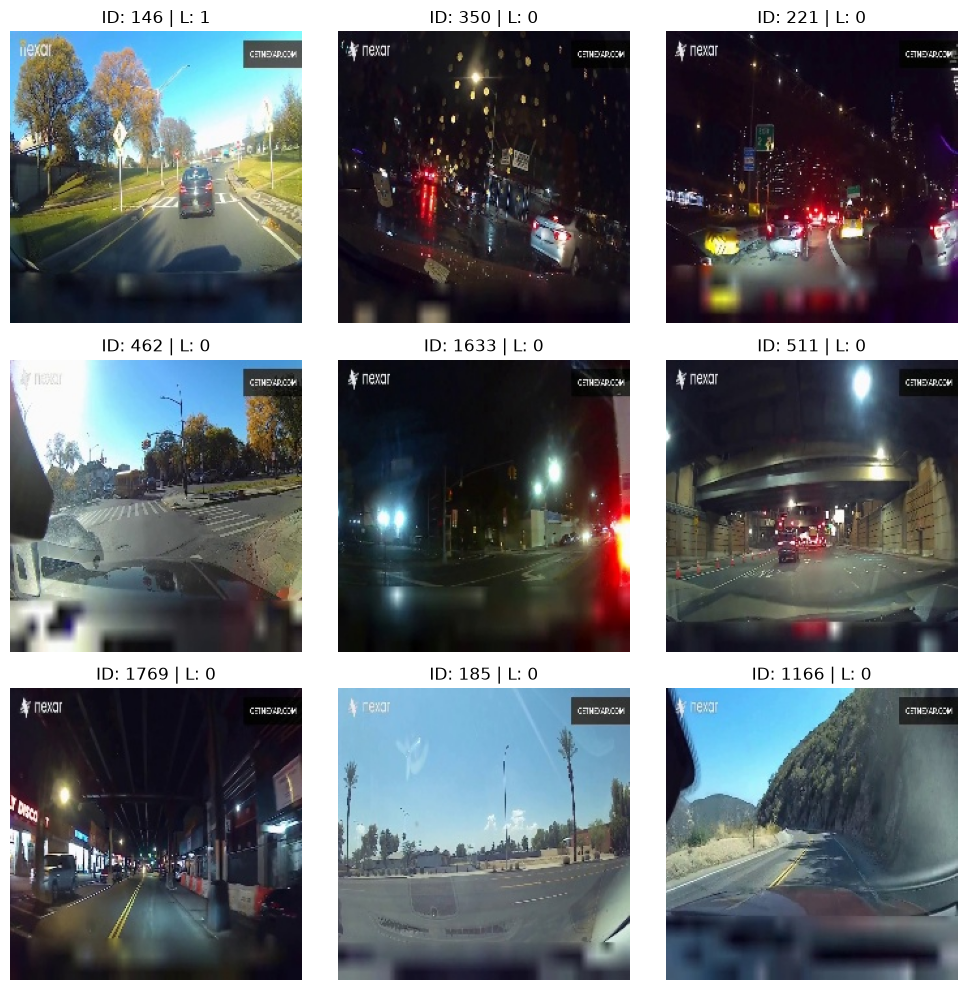

In [39]:
import random
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path


train_csv = Path("../data/processed/train_frames_v2.csv")
if not train_csv.exists():
    train_csv = Path("data/processed/train_frames_v2.csv")

df_train = pd.read_csv(train_csv)

sample_rows = df_train.sample(n=9, random_state=42).reset_index(drop=True)

plt.figure(figsize=(10, 10))
for i, row in sample_rows.iterrows():
    img_path = row["frame_path"]
    if not Path(img_path).exists():
        
        img_path = Path("..") / row["frame_path"] if not Path(row["frame_path"]).is_absolute() else row["frame_path"]
    
    img = cv2.imread(str(img_path))
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(3, 3, i + 1)
        plt.imshow(img)
        plt.title(f"ID: {row['video_id']} | L: {row['label']}")
        plt.axis("off")

plt.tight_layout()
plt.show()

In [41]:
# Final Integrity and Sanity Checks
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(PROCESSED_DIR / "train_frames_v2.csv")
val_df = pd.read_csv(PROCESSED_DIR / "val_frames_v2.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test_frames_v2.csv")

sol_path = PROCESSED_DIR / "solution_v2.csv"
if not sol_path.exists():
    # اگر فایل solution نبود، از روی تست فریم‌ها می‌سازیمش
    test_videos = test_df[["video_id"]].drop_duplicates().copy()
    test_videos.columns = ["id"]
    test_videos["target"] = 0  # مقدار پیش‌فرض
    test_videos.to_csv(sol_path, index=False)

sol_df = pd.read_csv(sol_path)

train_ids = set(train_df["video_id"].astype(str).str.zfill(5))
val_ids = set(val_df["video_id"].astype(str).str.zfill(5))
test_ids = set(test_df["video_id"].astype(str).str.zfill(5))

assert len(train_ids & val_ids) == 0, "Leakage: Train & Val overlap!"
assert len(train_ids & test_ids) == 0, "Leakage: Train & Test overlap!"
assert len(val_ids & test_ids) == 0, "Leakage: Val & Test overlap!"

for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    counts = df.groupby("video_id").size()
    assert (counts >= 5).all(), f"Error: {name} contains videos with < 5 frames!"

# سازگاری با نام‌گذاری ستون شناسه در solution (ممکن است id یا video_id باشد)
id_col = "id" if "id" in sol_df.columns else "video_id"
sol_ids = sol_df[id_col].astype(str).str.zfill(5)

assert (sol_ids.str.len() == 5).all(), "Error: solution_v2 id must be zero-padded 5 digits!"
assert test_ids.issubset(set(sol_ids)), "Error: IDs in solution_v2 do not match test frames!"

for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df), ("Solution", sol_df)]:
    assert df.isna().sum().sum() == 0, f"Error: Missing/NaN values found in {name}!"

for p in train_df["frame_path"].sample(min(5, len(train_df))):
    img_path = Path(p) if Path(p).exists() else Path("..") / p
    assert img_path.exists(), f"Error: File does not exist on disk: {img_path}"

print("All integrity and sanity checks passed successfully.")

All integrity and sanity checks passed successfully.
